In [22]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# ========= 这里改成你的学号 =========
STUDENT_ID = 20244080321

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]        {STUDENT_ID}")
print(f"[机器指纹]    {MACHINE_FP}")
print(f"[RUN_ID]      {RUN_ID}")


[Conda 环境] pyexp
[学号]        20244080321
[机器指纹]    5c9a6f22bf8d43e1
[RUN_ID]      20244080321-5c9a6f22bf8d43e1


# 实验1：NumPy 数组、数据类型与索引
操作任务：
1. 分别创建整数、浮点数和布尔值 ndarray，输出每个数组的 dtype、shape 和 ndim。解释 NumPy 数组的数据类型与 Python 列表的差别。
2. 用 np.arange(12) 创建一维数组，并分别变为形状 (3, 4) 和 (2, 3, 2) 的数组。展示数组内容，说明改变形状时元素总数必须满足什么条件。
3. 对形状为 (3, 4) 的数组完成以下索引：取第2行、取第1至第3列、取大于6的元素，并分别输出结果及其形状。
4. 使用 np.arange(10) 分别选出“小于2或大于7”和“大于3且小于7”的元素。使用括号配合 |、& 或 np.logical_or()、np.logical_and()。
5. 构造两个形状为 (2, 2) 的数组，对比 *、np.multiply() 与 @、np.matmul() 的结果，说明逐元素乘法与矩阵乘法的区别。


### 1.1 数组基础信息
分别创建整数、浮点数、布尔值ndarray，输出每个数组的dtype、shape、ndim，对比NumPy数组和Python列表差异。


In [23]:
import numpy as np

arr_int = np.array([1, 2, 3, 4], dtype=int)
arr_float = np.array([1.1, 2.2, 3.3, 4.4], dtype=float)
arr_bool = np.array([True, False, True, False], dtype=bool)

print("整数数组：")
print(f"内容：{arr_int}, dtype:{arr_int.dtype}, shape:{arr_int.shape}, ndim:{arr_int.ndim}\n")
print("浮点数数组：")
print(f"内容：{arr_float}, dtype:{arr_float.dtype}, shape:{arr_float.shape}, ndim:{arr_float.ndim}\n")
print("布尔数组：")
print(f"内容：{arr_bool}, dtype:{arr_bool.dtype}, shape:{arr_bool.shape}, ndim:{arr_bool.ndim}")


整数数组：
内容：[1 2 3 4], dtype:int64, shape:(4,), ndim:1

浮点数数组：
内容：[1.1 2.2 3.3 4.4], dtype:float64, shape:(4,), ndim:1

布尔数组：
内容：[ True False  True False], dtype:bool, shape:(4,), ndim:1


> 说明：
> NumPy ndarray：同构数组，全部元素类型一致，内存连续，支持向量化运算，计算速度快。本次运行得到dtype为int64、float64、bool。
> Python list：异构容器，可以存放不同类型的数据，内存分散，没有原生向量化运算。


### 1.2 数组形状重塑
使用np.arange(12)生成一维数组，分别reshape为(3,4)、(2,3,2)，观察结果，理解reshape约束条件。


In [24]:
a = np.arange(12)
print("原始一维数组：\n", a)

a34 = a.reshape(3, 4)
print("\nreshape(3,4)：\n", a34)

a232 = a.reshape(2, 3, 2)
print("\nreshape(2,3,2)：\n", a232)


原始一维数组：
 [ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4)：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2)：
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


> 说明：reshape要求新形状各个维度相乘的乘积等于数组总元素数量，本例 12 = 3*4 = 2*3*2；如果乘积不相等，会抛出报错。


### 1.3 数组索引操作
对(3,4)数组：取第2行；取1-3列；取大于6的元素，同时打印结果和shape。
注意numpy索引从0开始。


In [25]:
a = np.arange(12).reshape(3,4)
print("原数组 a:\n", a)

row2 = a[1, :]
print("\n取第2行：\n", row2, "  shape =", row2.shape)

col1_3 = a[:, 0:3]
print("\n取第1至第3列：\n", col1_3, "  shape =", col1_3.shape)

gt6 = a[a > 6]
print("\n取大于6的元素：\n", gt6, "  shape =", gt6.shape)


原数组 a:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

取第2行：
 [4 5 6 7]   shape = (4,)

取第1至第3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]   shape = (3, 3)

取大于6的元素：
 [ 7  8  9 10 11]   shape = (5,)


### 1.4 布尔索引筛选元素
np.arange(10)，筛选：小于2或大于7；大于3且小于7。
使用 |、& 或者 np.logical_or、np.logical_and。


In [26]:
a = np.arange(10)
print("原数组：", a)

res_or = a[(a < 2) | (a > 7)]
print("\n小于2 或 大于7：", res_or)

res_and = a[(a > 3) & (a < 7)]
print("大于3 且 小于7：", res_and)

# 函数版本
res_or2 = a[np.logical_or(a < 2, a > 7)]
res_and2 = a[np.logical_and(a > 3, a < 7)]
print("\nlogical_or版本：", res_or2)
print("logical_and版本：", res_and2)


原数组： [0 1 2 3 4 5 6 7 8 9]

小于2 或 大于7： [0 1 8 9]
大于3 且 小于7： [4 5 6]

logical_or版本： [0 1 8 9]
logical_and版本： [4 5 6]


### 1.5 逐元素乘法与矩阵乘法对比
构造两个(2,2)数组，对比 *、np.multiply() 和 @、np.matmul()，区分逐元素乘法和矩阵乘法。


In [27]:
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])
print("A = \n", A)
print("B = \n", B)

elem_mul = A * B
np_elem_mul = np.multiply(A,B)
print("\n逐元素乘法 A * B：\n", elem_mul)
print("np.multiply(A,B)：\n", np_elem_mul)

mat_mul = A @ B
np_mat_mul = np.matmul(A,B)
print("\n矩阵乘法 A @ B：\n", mat_mul)
print("np.matmul(A,B)：\n", np_mat_mul)


A = 
 [[1 2]
 [3 4]]
B = 
 [[5 6]
 [7 8]]

逐元素乘法 A * B：
 [[ 5 12]
 [21 32]]
np.multiply(A,B)：
 [[ 5 12]
 [21 32]]

矩阵乘法 A @ B：
 [[19 22]
 [43 50]]
np.matmul(A,B)：
 [[19 22]
 [43 50]]


> 说明：
> `*` 和 `np.multiply()`：**逐元素相乘**，对应位置元素单独相乘，两个数组shape必须相同。
> `@` 和 `np.matmul()`：**数学上的矩阵乘法**，遵循矩阵相乘规则，要求前一个矩阵的列数等于后一个矩阵的行数。


## 实验2：随机抽样、统计与缺失值
实验目的：熟悉NumPy随机数生成、抽样、随机排列、基础统计计算，理解np.nan缺失值对统计函数的影响

### 任务1
使用 np.random 生成1000个均值为70、标准差为10的模拟成绩；用np.clip将数值限制在0～100范围内。输出样本数、最小值、最大值、均值、标准差和极差。


In [28]:
# 生成正态分布成绩
scores = np.random.normal(loc=70, scale=10, size=1000)
# 限制在0~100
scores = np.clip(scores, 0, 100)

n = len(scores)
min_s = scores.min()
max_s = scores.max()
mean_s = scores.mean()
std_s = scores.std()
range_s = max_s - min_s

print(f"样本数：{n}")
print(f"最小值：{min_s:.2f}")
print(f"最大值：{max_s:.2f}")
print(f"均值：{mean_s:.2f}")
print(f"标准差：{std_s:.2f}")
print(f"极差：{range_s:.2f}")


样本数：1000
最小值：37.59
最大值：100.00
均值：70.53
标准差：9.96
极差：62.41


### 任务2
从 np.arange(1, 11) 中不放回地抽取5个整数，比较均匀抽样与按整数大小成比例加权抽样的写法。


In [29]:
arr = np.arange(1, 11)
# 均匀不放回抽样
sample_uniform = np.random.choice(arr, size=5, replace=False)
# 权重与数字大小成正比
p = arr / arr.sum()
sample_weighted = np.random.choice(arr, size=5, replace=False, p=p)

print("原数组：", arr)
print("均匀不放回抽样：", sample_uniform)
print("加权抽样（权重与数值成正比）：", sample_weighted)
print("各元素抽样概率：", np.round(p, 3))


原数组： [ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样： [3 9 2 1 4]
加权抽样（权重与数值成正比）： [ 8  4  6 10  9]
各元素抽样概率： [0.018 0.036 0.055 0.073 0.091 0.109 0.127 0.145 0.164 0.182]


### 任务3
分别演示随机排列后保留原数组和原地打乱数组，打印操作前后的原数组以说明两种方式的区别。


In [30]:
x = np.arange(1, 11)
print("操作前原数组 x：", x)

# permutation：返回新数组，原数组不变
x_perm = np.random.permutation(x)
print("\npermutation 生成新数组：", x_perm)
print("permutation 后原数组 x：", x)

# shuffle：原地打乱，直接修改原数组
np.random.shuffle(x)
print("\nshuffle 之后原数组 x：", x)


操作前原数组 x： [ 1  2  3  4  5  6  7  8  9 10]

permutation 生成新数组： [10  7  6  9  8  3  2  4  5  1]
permutation 后原数组 x： [ 1  2  3  4  5  6  7  8  9 10]

shuffle 之后原数组 x： [ 7  5  6  8  1 10  4  3  2  9]


### 任务4
将模拟成绩的第10、20、30个值设为 np.nan。比较普通均值和忽略缺失值后的均值，统计缺失值个数，并说明nan对普通统计函数的影响。
> 注意：数组下标从0开始，第10、20、30个对应索引9、19、29


In [31]:
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan

mean_raw = scores_nan.mean()
mean_skip_nan = np.nanmean(scores_nan)
nan_num = np.isnan(scores_nan).sum()

print(f"直接mean（含nan）：{mean_raw}")
print(f"nanmean（跳过缺失值）：{mean_skip_nan:.2f}")
print(f"缺失值nan总个数：{nan_num}")


直接mean（含nan）：nan
nanmean（跳过缺失值）：70.50
缺失值nan总个数：3


### 任务5
将含缺失值的模拟成绩及其序号整理成内存中的表格变量，供实验4直接使用；不要写入磁盘。


In [32]:
index_arr = np.arange(len(scores_nan))
# 内存表格，只存在内存，不保存文件
score_table = {
    "index": index_arr,
    "score": scores_nan
}
print("内存表格构造完成，可直接供实验4调用")
print("前10条数据：")
for i in range(10):
    print(score_table["index"][i], score_table["score"][i])


内存表格构造完成，可直接供实验4调用
前10条数据：
0 73.57787360348283
1 75.60784526368235
2 80.83051243175277
3 80.53802052034902
4 56.22330632042909
5 60.62174960084877
6 75.1503526720866
7 75.1378595091221
8 75.15047686306048
9 nan


# 实验3：Scipy数值计算与Matplotlib可视化
## 实验说明
本实验使用`numpy`、`scipy`完成线性方程组求解、方程求根、函数极小值求解、独立样本t检验，并用`matplotlib`绘制统计直方图、箱线图以及函数曲线。
1. 任务1：`scipy.linalg.solve`求解二元线性方程组 $3x+y=9,\ x+2y=8$，使用矩阵乘法验证结果。
2. 任务2：`scipy.optimize.root`求解一元二次方程 $x^2-2=0$ 的正负根。
3. 任务3：`scipy.optimize.minimize`求二次函数 $f(x)=x^2+x+2$ 的极小值，和解析解对比。
4. 任务4：`scipy.stats.ttest_ind`生成两组正态随机样本，进行独立样本t检验并判断显著性。
5. 任务5：Matplotlib绘图：
   - 子图1：样本直方图 + 箱线图，观察正态分布样本特征
   - 子图2：同一坐标系绘制 $y=x、y=x^2、y=x^3 \ (0 \le x \le 5)$ 函数曲线


===== 任务1 解线性方程组 3x+y=9，x+2y=8 =====
解：x = 2.0, y = 3.0
代入验证结果：[9. 8.]，与右端b=[9 8]相等

===== 任务2 求方程 x² - 2 = 0 的正负根 =====
正根：
是否成功：True，根 = 1.414214，函数值f(x)=8.88e-16
负根：
是否成功：True，根 = -1.414214，函数值f(x)=8.88e-16

===== 任务3 求 f(x)=x²+x+2 的最小值 =====
数值解极小点：x = -0.500000
数值解极小值：f(x) = 1.750000
解析解：极小点 x=-0.5，极小值=1.75

===== 任务4 独立样本t检验 =====
t统计量：-8.5515
p值：3.2930e-15
显著性水平0.05：p < 0.05，拒绝原假设，两组均值存在显著差异



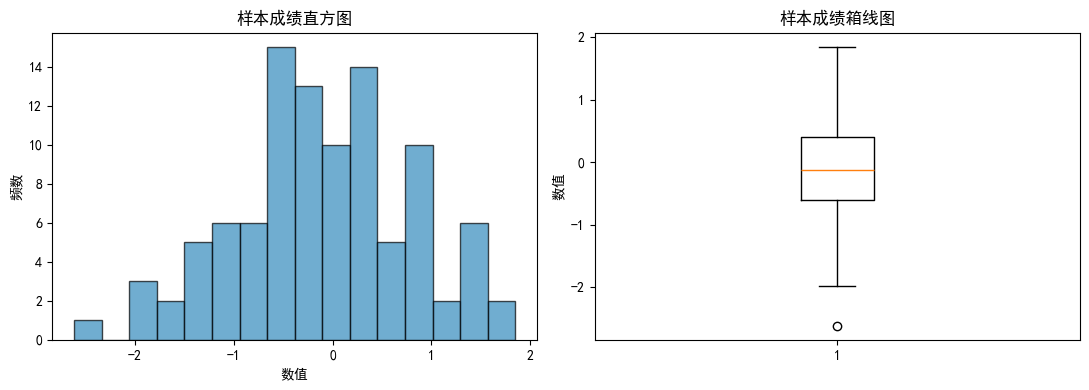

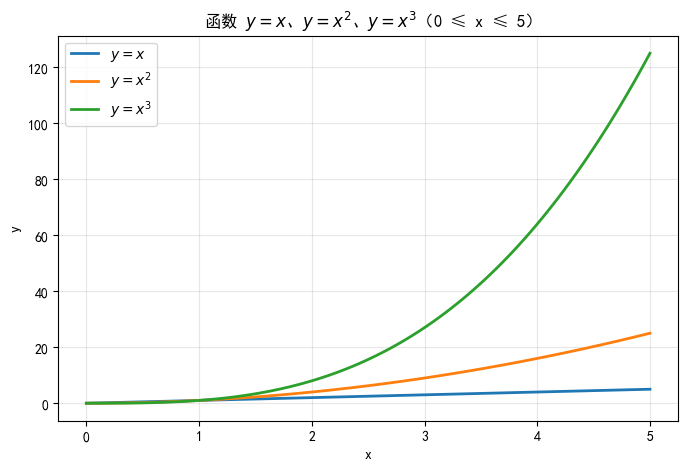

In [33]:
import numpy as np
from scipy import linalg, optimize, stats
import matplotlib.pyplot as plt

# -------------------------- 任务1：scipy.linalg.solve 解线性方程组 --------------------------
print("===== 任务1 解线性方程组 3x+y=9，x+2y=8 =====")
A = np.array([[3, 1],
              [1, 2]])
b = np.array([9, 8])
sol = linalg.solve(A, b)
print(f"解：x = {sol[0]}, y = {sol[1]}")
# NumPy代入验证
check = A @ sol
print(f"代入验证结果：{check}，与右端b={b}相等\n")

# -------------------------- 任务2：optimize.root 求 x²-2=0 的正负根 --------------------------
print("===== 任务2 求方程 x² - 2 = 0 的正负根 =====")
def f(x):
    return x ** 2 - 2

# 正根，初始猜测2
res_pos = optimize.root(f, x0=2)
# 负根，初始猜测-2
res_neg = optimize.root(f, x0=-2)

print("正根：")
print(f"是否成功：{res_pos.success}，根 = {res_pos.x[0]:.6f}，函数值f(x)={f(res_pos.x[0]):.2e}")
print("负根：")
print(f"是否成功：{res_neg.success}，根 = {res_neg.x[0]:.6f}，函数值f(x)={f(res_neg.x[0]):.2e}\n")

# -------------------------- 任务3：optimize.minimize 求 f(x)=x²+x+2 最小值 --------------------------
print("===== 任务3 求 f(x)=x²+x+2 的最小值 =====")
def fun(x):
    return x**2 + x + 2

res_min = optimize.minimize(fun, x0=0)
print(f"数值解极小点：x = {res_min.x[0]:.6f}")
print(f"数值解极小值：f(x) = {res_min.fun:.6f}")
# 解析解求导：f’=2x+1=0 → x=-0.5，f(-0.5)=1.75
print(f"解析解：极小点 x=-0.5，极小值=1.75\n")

# -------------------------- 任务4：独立样本t检验 --------------------------
print("===== 任务4 独立样本t检验 =====")
np.random.seed(42)   # 固定随机种子保证结果可复现
s1 = np.random.normal(loc=0, scale=1, size=100)
s2 = np.random.normal(loc=1, scale=1, size=100)
t_stat, p_value = stats.ttest_ind(s1, s2)
print(f"t统计量：{t_stat:.4f}")
print(f"p值：{p_value:.4e}")
alpha = 0.05
if p_value < alpha:
    print(f"显著性水平0.05：p < 0.05，拒绝原假设，两组均值存在显著差异\n")
else:
    print(f"显著性水平0.05：p ≥ 0.05，不能拒绝原假设\n")

# -------------------------- 任务5 Matplotlib可视化 --------------------------
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 图1：直方图 + 箱线图（使用上面s1样本作为成绩数据）
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(11, 4))
ax_hist.hist(s1, bins=16, alpha=0.7, color="#348ABD", edgecolor="black")
ax_hist.set_title("样本成绩直方图")
ax_hist.set_xlabel("数值")
ax_hist.set_ylabel("频数")

ax_box.boxplot(s1)
ax_box.set_title("样本成绩箱线图")
ax_box.set_ylabel("数值")
plt.tight_layout()
plt.show()

# 图2：同一坐标系绘制 y=x, y=x², y=x³，0≤x≤5
x = np.linspace(0, 5, 100)
y_1 = x
y_2 = x**2
y_3 = x**3

plt.figure(figsize=(8, 5))
plt.plot(x, y_1, label="$y=x$", linewidth=2)
plt.plot(x, y_2, label="$y=x^2$", linewidth=2)
plt.plot(x, y_3, label="$y=x^3$", linewidth=2)
# 改这里！去掉区间的$，不用\le，直接中文≤，避开LaTeX报错
plt.title("函数 $y=x$、$y=x^2$、$y=x^3$（0 ≤ x ≤ 5）")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 实验4：pandas Series、DataFrame 与内存中的CSV读写
## 实验目的
掌握 pandas 的 DataFrame 创建、索引选取（loc / iloc）、数据计算、分组聚合、transform、filter、协方差与相关系数等常用操作。
数据集：学生分组+三科成绩，行索引设置为学生姓名。
任务清单：
1. 创建DataFrame，新增Total总分、Average平均分；查看索引、列名、前3行、描述统计
2. loc、iloc读取Carol记录；筛选平均分≥80学生
3. mean(axis=0) 列均值；mean(axis=1) 每行学生均值
4. apply求单科最高分；agg一次性求每科min/mean/max；rank排名
5. groupby分组统计人数、三科平均分；transform增加本组Python平均分
6. groupby.filter 保留Python组平均分≥80的组别
7. 三科协方差矩阵、皮尔逊相关矩阵，并解释含义


In [34]:
import pandas as pd
import numpy as np

# ========== 任务1：创建DataFrame，设置姓名为行索引，新增总分、平均分 ==========
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")  # 将Name设为行索引

# 新增总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("="*50)
print("【任务1】行索引：", df.index.tolist())
print("【任务1】列名：", df.columns.tolist())
print("\n【任务1】前3行数据：")
print(df.head(3))
print("\n【任务1】基本统计信息：")
print(df.describe())


# ========== 任务2：loc、iloc读取Carol；筛选平均分≥80 ==========
print("\n"+"="*50)
print("【任务2】loc读取Carol（标签索引）：")
print(df.loc["Carol"])

print("\n【任务2】iloc读取Carol（位置索引，Carol在第2行，下标=1）：")
print(df.iloc[1])

print("\n【任务2】平均分不低于80的学生：")
high_avg = df[df["Average"] >= 80]
print(high_avg)


# ========== 任务3：mean(axis=0) 列均值；mean(axis=1)行均值 ==========
print("\n"+"="*50)
print("【任务3】axis=0：各科列均值（每科平均分）")
col_mean = df[["Math","English","Python"]].mean(axis=0)
print(col_mean)

print("\n【任务3】axis=1：每个学生三科行均值（和Average列一致）")
row_mean = df[["Math","English","Python"]].mean(axis=1)
print(row_mean)


# ========== 任务4：apply求最高分；agg一次求min/mean/max；rank排名 ==========
print("\n"+"="*50)
# apply：每行取三科最高分
df["Highest"] = df[["Math","English","Python"]].apply(lambda row: row.max(), axis=1)
print("【任务4】增加Highest最高分列：")
print(df)

print("\n【任务4】agg：每科一次性求最小值、均值、最大值")
agg_res = df[["Math","English","Python"]].agg(["min","mean","max"])
print(agg_res)

print("\n【任务4】对Python成绩rank排名（降序，分数越高名次越靠前）")
df["Python_Rank"] = df["Python"].rank(method="min", ascending=False)
print(df[["Python","Python_Rank"]])


# ========== 任务5：分组统计 + transform ==========
print("\n"+"="*50)
print("【任务5】按Group分组：每组人数、三科平均分")
group_stat = df.groupby("Group").agg(
    人数=("Math", "count"),
    Math平均分=("Math","mean"),
    English平均分=("English","mean"),
    Python平均分=("Python","mean")
)
print(group_stat)

# transform：给每行新增【本组Python平均分】
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n【任务5】增加本组Python平均分：")
print(df[["Group","Python","Group_Python_Mean"]])


# ========== 任务6：filter，保留组内Python平均分≥80的组 ==========
print("\n"+"="*50)
print("【任务6】filter：保留Python组平均分≥80的组")
group_filtered = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print(group_filtered)


# ========== 任务7：协方差矩阵、皮尔逊相关矩阵 + 文字解释 ==========
print("\n"+"="*50)
score_cols = ["Math","English","Python"]
cov_matrix = df[score_cols].cov()
corr_matrix = df[score_cols].corr(method="pearson")

print("【任务7】三科协方差矩阵：")
print(cov_matrix)
print("\n【任务7】皮尔逊相关系数矩阵：")
print(corr_matrix)

print("\n【任务7】解释示例（以Math和Python为例）：")
print("协方差符号：如果为正，代表两科成绩同向变化；负则反向。")
print("皮尔逊相关系数范围[-1,1]：越接近1强正相关，接近-1强负相关，接近0线性无关。")


【任务1】行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
【任务1】列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

【任务1】前3行数据：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

【任务1】基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

【任务2】loc读取Carol（标签索引